# Lab Benchmark: JEV vs Gemini
So sánh độ chính xác, chi phí, độ trễ giữa JEV và Gemini (gemini-1.5-flash) dựa trên bộ dữ liệu 100 tin nhắn.


In [6]:
# 1. Khởi tạo và Load biến môi trường
import pandas as pd
import requests
import time
import os
import json
from dotenv import load_dotenv
import google.generativeai as genai
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from IPython.display import display

load_dotenv()
jev_api = os.getenv("jev_api")
gemini_api = os.getenv("gemini_api")

if not jev_api or not gemini_api:
    print("⚠️ Cảnh báo: Thiếu API keys trong file .env!")
else:
    print("✅ Load API keys thành công!")

genai.configure(api_key=gemini_api)


✅ Load API keys thành công!


In [7]:
# 2. Đọc dữ liệu
file_path = "bo_du_lieu_100_can_bang.xlsx"
try:
    df = pd.read_excel(file_path)
    print(f"✅ Đọc dữ liệu thành công! Số lượng dòng: {len(df)}")
    display(df.head(2))
except Exception as e:
    print(f"❌ Lỗi đọc dữ liệu: {e}")



✅ Đọc dữ liệu thành công! Số lượng dòng: 100


,ID,Tin nhắn,Kênh,Mã thread,Người gửi,Vai trò,Nhóm / phạm vi,Dự án,Thời gian,Có file?,...,Thiếu context?,Lý do gán nhãn,Ứng viên regex?,Mã pattern,Kết quả model trả lời,Độ tin cậy trả lời,Kết quả model ghi nhớ,Độ tin cậy ghi nhớ,Review cuối,Ghi chú
0,MSG001,Vậy chốt theo đó nha anh?,GROUP,TH001,Mai,Marketing,Dự án Nova,Dự án Nova,2026-10-05 08:12,Không,...,Có,"Thiếu thread trước nên không rõ ""đó"" là gì; ch...",Không,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,MSG002,Anh chốt giá như em nói hôm qua nhé.,DM,TH002,Huyền,Kinh doanh,Dự án Atlas,Dự án Atlas,2026-10-05 08:17,Không,...,Có,Cần hỏi lại vì không nêu mức giá cụ thể; chốt ...,Có,M05,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
# 3. Hàm gọi API JEV và Gemini

def call_jev(state_text):
    url = "https://api.typesafe.ai/v1/systemone"
    headers = {
        "Authorization": f"Bearer {jev_api}",
        "Content-Type": "application/json"
    }
    payload = {
        "state": state_text,
        "model": "jev-latest",
        "questions": {
            "nhom_nhan": {
                "type": "choice",
                "instructions": "Phân loại tin nhắn này vào nhóm nhãn phù hợp.",
                "criteria": {
                    "A - Trả lời + Ghi nhớ": "Cần trả lời và cần ghi nhớ",
                    "B - Trả lời + Không ghi nhớ": "Cần trả lời nhưng không cần ghi nhớ",
                    "C - Không trả lời + Ghi nhớ": "Không cần trả lời nhưng cần ghi nhớ",
                    "D - Không trả lời + Không ghi nhớ": "Không cần trả lời và không cần ghi nhớ"
                }
            }
        }
    }
    
    start_time = time.time()
    try:
        res = requests.post(url, headers=headers, json=payload, timeout=30)
        res.raise_for_status()
        data = res.json()
        latency = time.time() - start_time
        
        answer = data["answers"]["nhom_nhan"]["choice"]
        in_tokens = data["usage"]["input_tokens"]
        out_tokens = data["usage"]["output_tokens"]
        
        return answer, latency, in_tokens, out_tokens, None
    except Exception as e:
        latency = time.time() - start_time
        return None, latency, 0, 0, str(e)


def call_gemini(prompt_text):
    # Sử dụng gemini-1.5-flash (tương ứng với yêu cầu flash-3.8 của bạn, bản chuẩn của Google hiện tại là 1.5-flash)
    model = genai.GenerativeModel('gemini-3.8-flash')
    
    start_time = time.time()
    try:
        response = model.generate_content(prompt_text)
        latency = time.time() - start_time
        
        answer = response.text.strip()
        in_tokens = response.usage_metadata.prompt_token_count
        out_tokens = response.usage_metadata.candidates_token_count
        
        return answer, latency, in_tokens, out_tokens, None
    except Exception as e:
        latency = time.time() - start_time
        return None, latency, 0, 0, str(e)



In [9]:
# 4. Chạy Benchmark trên 100 tin nhắn

# Cấu hình tính phí giả định (USD trên 1M tokens) - Cập nhật giá thực tế nếu cần
JEV_PRICE_IN = 0.042
JEV_PRICE_OUT = 0.0
GEMINI_PRICE_IN = 0.75
GEMINI_PRICE_OUT = 3.75

features = ['Tin nhắn', 'Kênh', 'Mã thread', 'Người gửi', 'Vai trò', 'Nhóm / phạm vi', 'Dự án', 'Thời gian', 'Có file?', 'Tên file', 'Nhắc lãnh đạo?', 'Loại tin']

# Chuẩn bị dữ liệu results
results = []
for idx, row in df.iterrows():
    results.append({
        "ID": row.get("ID", idx),
        "Ground_Truth": row.get("Nhóm nhãn", ""),
        "State_Text": "",
        "Gemini_Prompt": ""
    })

print("🚀 Bắt đầu benchmark...")

# ---- 4.1 Chạy JEV ----
print("\n--- ĐANG CHẠY JEV ---")
jev_latencies = []
for idx, row in df.iterrows():
    # Format input
    state_text = "Thông tin đầu vào:\n"
    for f in features:
        if pd.notna(row.get(f)):
            state_text += f"- {f}: {row[f]}\n"
            
    results[idx]["State_Text"] = state_text
            
    jev_ans, jev_lat, jev_in, jev_out, jev_err = call_jev(state_text)
    
    results[idx]["JEV_Pred"] = jev_ans
    results[idx]["JEV_Latency"] = jev_lat
    results[idx]["JEV_InTokens"] = jev_in
    results[idx]["JEV_OutTokens"] = jev_out
    results[idx]["JEV_Error"] = jev_err
    
    if jev_lat:
        jev_latencies.append(jev_lat)
    else:
        jev_latencies.append(0)
    
    count = idx + 1
    if count % 10 == 0:
        avg_lat = sum(jev_latencies[-10:]) / 10
        print(f"[JEV] ✅ Đã xong {count}/{len(df)} | Avg latency 10 req gần nhất: {avg_lat:.2f}s")
        
    time.sleep(0.5)

# ---- 4.2 Chạy Gemini ----
print("\n--- ĐANG CHẠY GEMINI ---")
gemini_latencies = []
for idx, row in df.iterrows():
    state_text = results[idx]["State_Text"]
    gemini_prompt = f"Phân loại tin nhắn sau vào đúng MỘT trong 4 nhóm nhãn sau. Chỉ in ra chính xác tên nhóm nhãn (ví dụ: 'A - Trả lời + Ghi nhớ'), không giải thích thêm.\n\nNhóm nhãn:\nA - Trả lời + Ghi nhớ\nB - Trả lời + Không ghi nhớ\nC - Không trả lời + Ghi nhớ\nD - Không trả lời + Không ghi nhớ\n\n{state_text}"
    
    gem_ans, gem_lat, gem_in, gem_out, gem_err = call_gemini(gemini_prompt)
    
    if gem_ans:
        for label in ["A - Trả lời + Ghi nhớ", "B - Trả lời + Không ghi nhớ", "C - Không trả lời + Ghi nhớ", "D - Không trả lời + Không ghi nhớ"]:
            if label in gem_ans:
                gem_ans = label
                break
                
    results[idx]["Gemini_Pred"] = gem_ans
    results[idx]["Gemini_Latency"] = gem_lat
    results[idx]["Gemini_InTokens"] = gem_in
    results[idx]["Gemini_OutTokens"] = gem_out
    results[idx]["Gemini_Error"] = gem_err
    
    if gem_lat:
        gemini_latencies.append(gem_lat)
    else:
        gemini_latencies.append(0)
    
    count = idx + 1
    if count % 10 == 0:
        avg_lat = sum(gemini_latencies[-10:]) / 10
        print(f"[Gemini] ✅ Đã xong {count}/{len(df)} | Avg latency 10 req gần nhất: {avg_lat:.2f}s")
        
    time.sleep(1.0)

# Dọn dẹp các field tạm (State_Text, Gemini_Prompt) không cần thiết
for r in results:
    r.pop("State_Text", None)
    r.pop("Gemini_Prompt", None)

df_res = pd.DataFrame(results)
print("\n🎉 Benchmark hoàn thành!")
display(df_res.head())

🚀 Bắt đầu benchmark...

--- ĐANG CHẠY JEV ---
[JEV] ✅ Đã xong 10/100 | Avg latency 10 req gần nhất: 0.38s
[JEV] ✅ Đã xong 20/100 | Avg latency 10 req gần nhất: 0.35s
[JEV] ✅ Đã xong 30/100 | Avg latency 10 req gần nhất: 0.34s
[JEV] ✅ Đã xong 40/100 | Avg latency 10 req gần nhất: 0.38s
[JEV] ✅ Đã xong 50/100 | Avg latency 10 req gần nhất: 0.60s
[JEV] ✅ Đã xong 60/100 | Avg latency 10 req gần nhất: 0.72s
[JEV] ✅ Đã xong 70/100 | Avg latency 10 req gần nhất: 0.46s
[JEV] ✅ Đã xong 80/100 | Avg latency 10 req gần nhất: 0.42s
[JEV] ✅ Đã xong 90/100 | Avg latency 10 req gần nhất: 0.36s
[JEV] ✅ Đã xong 100/100 | Avg latency 10 req gần nhất: 0.40s

--- ĐANG CHẠY GEMINI ---
[Gemini] ✅ Đã xong 10/100 | Avg latency 10 req gần nhất: 3.32s
[Gemini] ✅ Đã xong 20/100 | Avg latency 10 req gần nhất: 2.66s
[Gemini] ✅ Đã xong 30/100 | Avg latency 10 req gần nhất: 3.21s
[Gemini] ✅ Đã xong 40/100 | Avg latency 10 req gần nhất: 2.57s
[Gemini] ✅ Đã xong 50/100 | Avg latency 10 req gần nhất: 2.67s
[Gemini] ✅ Đ

,ID,Ground_Truth,JEV_Pred,JEV_Latency,JEV_InTokens,JEV_OutTokens,JEV_Error,Gemini_Pred,Gemini_Latency,Gemini_InTokens,Gemini_OutTokens,Gemini_Error
0,MSG001,A - Trả lời + Ghi nhớ,A - Trả lời + Ghi nhớ,0.319035,530,88,None,B - Trả lời + Không ghi nhớ,3.077839,206,9,None
1,MSG002,A - Trả lời + Ghi nhớ,A - Trả lời + Ghi nhớ,0.355660,536,88,None,A - Trả lời + Ghi nhớ,3.932356,210,9,None
2,MSG003,D - Không trả lời + Không ghi nhớ,B - Trả lời + Không ghi nhớ,0.292515,537,88,None,B - Trả lời + Không ghi nhớ,3.573362,214,9,None
3,MSG004,C - Không trả lời + Ghi nhớ,B - Trả lời + Không ghi nhớ,0.348093,549,88,None,A - Trả lời + Ghi nhớ,1.349728,220,9,None
4,MSG005,C - Không trả lời + Ghi nhớ,A - Trả lời + Ghi nhớ,0.386642,546,88,None,B - Trả lời + Không ghi nhớ,3.805317,222,9,None


In [10]:
# 5. Lưu kết quả ra file
output_file = "benchmark_results_jev_vs_gemini.xlsx"
df_res.to_excel(output_file, index=False)
print(f"💾 Đã lưu kết quả chi tiết ra file: {output_file}")



💾 Đã lưu kết quả chi tiết ra file: benchmark_results_jev_vs_gemini.xlsx


--- KẾT QUẢ TỔNG QUAN ---
JEV:    Accuracy = 42.0% | Avg Latency = 0.44s | Total Cost = $0.00229
Gemini: Accuracy = 47.0% | Avg Latency = 2.65s | Total Cost = $0.01989


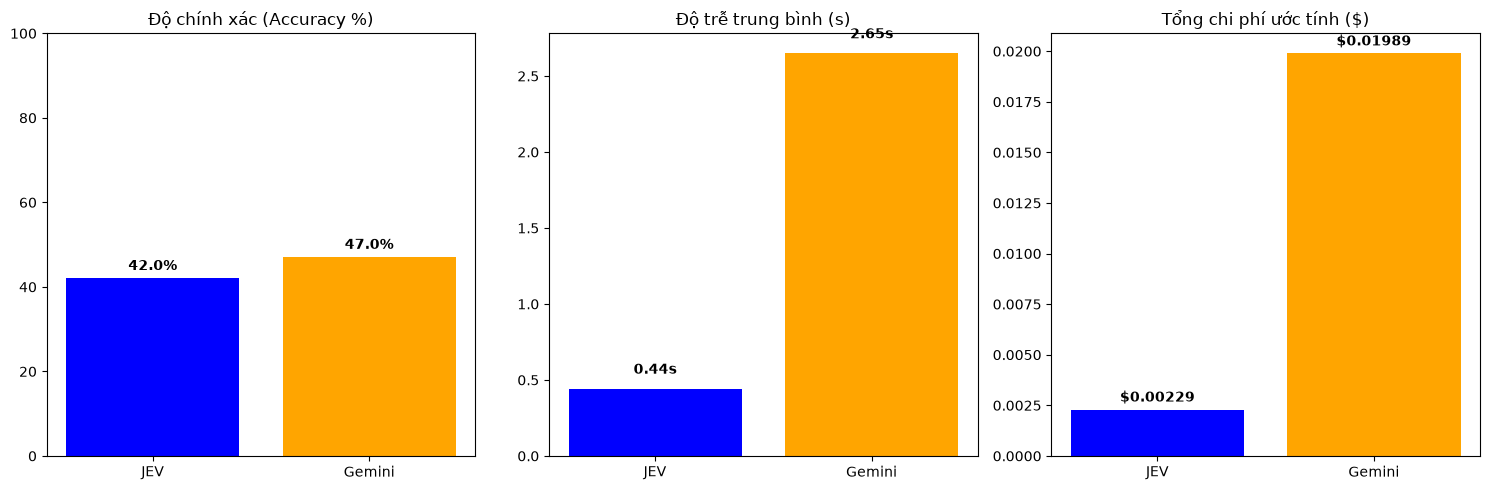

In [11]:
# 6. Tính toán các chỉ số và vẽ Dashboard

# --- Tính Accuracy ---
df_valid_jev = df_res[df_res['JEV_Error'].isnull()]
df_valid_gem = df_res[df_res['Gemini_Error'].isnull()]

acc_jev = accuracy_score(df_valid_jev['Ground_Truth'], df_valid_jev['JEV_Pred']) if not df_valid_jev.empty else 0
acc_gem = accuracy_score(df_valid_gem['Ground_Truth'], df_valid_gem['Gemini_Pred']) if not df_valid_gem.empty else 0

# --- Tính Latency (trung bình) ---
lat_jev = df_res['JEV_Latency'].mean()
lat_gem = df_res['Gemini_Latency'].mean()

# --- Tính Cost (ước tính) ---
cost_jev = (df_res['JEV_InTokens'].sum() / 1e6 * JEV_PRICE_IN) + (df_res['JEV_OutTokens'].sum() / 1e6 * JEV_PRICE_OUT)
cost_gem = (df_res['Gemini_InTokens'].sum() / 1e6 * GEMINI_PRICE_IN) + (df_res['Gemini_OutTokens'].sum() / 1e6 * GEMINI_PRICE_OUT)

print(f"--- KẾT QUẢ TỔNG QUAN ---")
print(f"JEV:    Accuracy = {acc_jev*100:.1f}% | Avg Latency = {lat_jev:.2f}s | Total Cost = ${cost_jev:.5f}")
print(f"Gemini: Accuracy = {acc_gem*100:.1f}% | Avg Latency = {lat_gem:.2f}s | Total Cost = ${cost_gem:.5f}")

# --- Vẽ Dashboard ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 1. Biểu đồ Accuracy
axes[0].bar(['JEV', 'Gemini'], [acc_jev*100, acc_gem*100], color=['blue', 'orange'])
axes[0].set_title('Độ chính xác (Accuracy %)')
axes[0].set_ylim(0, 100)
for i, v in enumerate([acc_jev*100, acc_gem*100]):
    axes[0].text(i, v + 2, f"{v:.1f}%", ha='center', fontweight='bold')

# 2. Biểu đồ Latency
axes[1].bar(['JEV', 'Gemini'], [lat_jev, lat_gem], color=['blue', 'orange'])
axes[1].set_title('Độ trễ trung bình (s)')
for i, v in enumerate([lat_jev, lat_gem]):
    axes[1].text(i, v + 0.1, f"{v:.2f}s", ha='center', fontweight='bold')

# 3. Biểu đồ Cost
axes[2].bar(['JEV', 'Gemini'], [cost_jev, cost_gem], color=['blue', 'orange'])
axes[2].set_title('Tổng chi phí ước tính ($)')
for i, v in enumerate([cost_jev, cost_gem]):
    axes[2].text(i, v + (max(cost_jev, cost_gem)*0.02), f"${v:.5f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

